# Module 9 Assignment: Exploratory Data Analysis and Visualization
**CS 5045: Computation for the Data Sciences**

**Name:** _Poukinimpo Blaise Logou

---

Complete each section below by filling in the blanks marked `__________` or writing code where indicated. Run all cells top to bottom and make sure there are no errors before submitting.

**Dataset:** `data.csv`, US air quality monitoring data, 300 readings across 6 cities spread across 2023.
The file is in the `Datasets/` folder one level up from this notebook.

**Columns:** `city` (str), `date` (str), `pm25` (float, ug/m3), `ozone` (float, ppm),
`temp_c` (float, Celsius), `humidity` (int, %)

**EPA PM2.5 thresholds:**
- Good: pm25 < 12
- Moderate: 12 <= pm25 < 20
- Unhealthy: pm25 >= 20

Commit and push this notebook (`hw9.ipynb`) to your fork on GitHub. No Canvas upload needed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset once at the top. All sections use this DataFrame.
df = pd.read_csv("C:/CS5045DS/module9/data (1).csv")

## Section 1: Load and Inspect

Before doing any analysis, run the four-line audit to confirm the data loaded correctly.

In [2]:
# 1a. Print the number of rows and columns.
#     Expected: (300, 6)
print("Shape:", df.shape)

# 1b. Print the data type of each column.
print("\nColumn types:")
print(df.dtypes)

# 1c. Print summary statistics for all numeric columns, rounded to 2 decimal places.
print("\nSummary statistics:")
numeric_cols = ['pm25', 'ozone', 'temp_c', 'humidity']
print(df[numeric_cols].describe().round(2))

# 1d. Print the count of missing values in each column.
#     Expected: all zeros for a clean dataset.
print("\nMissing values per column:")
print(df.isnull().sum())

Shape: (300, 6)

Column types:
city         object
date         object
pm25        float64
ozone       float64
temp_c      float64
humidity      int64
dtype: object

Summary statistics:
         pm25   ozone  temp_c  humidity
count  300.00  300.00  300.00     300.0
mean    12.94    0.05   14.84      58.7
std      3.63    0.01   12.16      14.0
min      3.70    0.03  -14.60      19.0
25%     10.80    0.04    5.85      53.0
50%     13.20    0.05   16.05      61.0
75%     15.20    0.06   25.30      68.0
max     23.70    0.08   37.30      89.0

Missing values per column:
city        0
date        0
pm25        0
ozone       0
temp_c      0
humidity    0
dtype: int64


## Section 2: Distribution

A histogram shows the shape of a single numeric variable: where values cluster, how spread out they are, and whether any extreme values exist.

**Operation:** Aggregate + Communicate

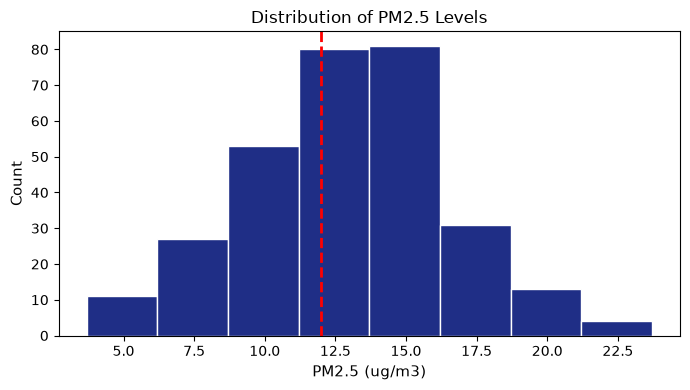

In [4]:
# 2a. Complete the histogram below.
#     Fill in: the column name to plot, the number of bins, and a descriptive title.
#     Use the pm25 column. Try 8 bins.

fig, ax = plt.subplots(figsize=(7, 4))

df['pm25'].plot(kind='hist', bins=8, ax=ax, color="#1F2E86", edgecolor='white')

ax.set_title('Distribution of PM2.5 Levels')
ax.set_xlabel('PM2.5 (ug/m3)', fontsize=11)
ax.set_ylabel('Count', fontsize=11)

# 2b. Add a vertical reference line at PM2.5 = 12 (the EPA 'Good' threshold).
#     Hint: use ax.axvline() with linestyle='--'.
ax.axvline(x=12, color='red', linestyle='--', linewidth=2)

plt.tight_layout()
plt.show()

**2c. Interpret the histogram.** In 1-2 sentences: where do most PM2.5 values cluster? Do any values appear extreme compared to the rest?

**Your answer:** The PM2.5 values cluster mostly at 10 ug/m3, 12.5 and 15 ug/m3. the value 12.5ug/m3 appear to be extreme.

## Section 3: Relationship

A scatter plot reveals whether two continuous variables move together. This is the Communicate operation applied to a two-variable question.

**Operation:** Communicate

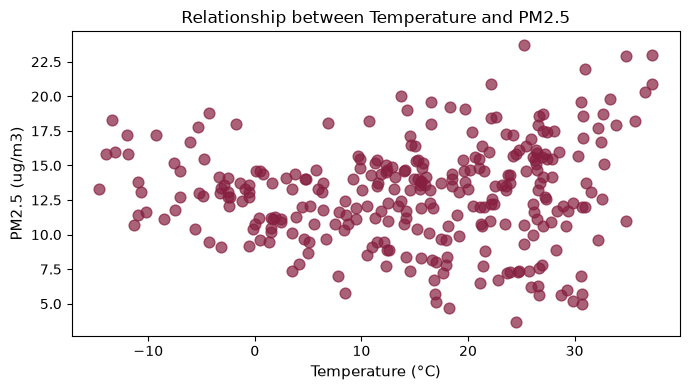

Saved: scatter_output.png


In [5]:
# 3a. Complete the scatter plot below.
#     Fill in: the x-axis column, the y-axis column, the x-axis label, and the title.
#     Explore the relationship between temperature (temp_c) and PM2.5 (pm25).

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(df['temp_c'], df['pm25'], alpha=0.7, color='#861F41', s=60)

ax.set_title('Relationship between Temperature and PM2.5')
ax.set_xlabel('Temperature (°C)', fontsize=11)
ax.set_ylabel('PM2.5 (ug/m3)', fontsize=11)

plt.tight_layout()
plt.savefig('scatter_output.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: scatter_output.png')

**3b. Interpret the scatter.** In 1-2 sentences: do you see a pattern? Remember: a pattern in observational data is a hypothesis, not a proven relationship. Write your observation using careful language ("the data suggests...", not "this proves...").

**Your answer:** The relationship between temperature and PM2.5 is weak at [10°C 15°C] and 30°C above. The highest PM2.5 values are [20µg/m³ to 23] and the temperature 27°C and the concentration ranges between 10 and 20 μg/m³. The data suggest that there's no clear, consistent pattern.

## Section 4: Category Comparison

GroupBy collapses many rows into one summary per group. A bar chart then communicates that summary.

**Operations:** Aggregate + Communicate

In [6]:
# 4a. First, add an 'aq_category' column to df.
#     Use the EPA thresholds from the top of the notebook.
#     You may use .apply() with a helper function, or pd.cut().

def aq_label(v):
    """
    TRANSFORM: classify a PM2.5 value into an EPA air quality category.

    Parameters:
        v (float) -- PM2.5 concentration in ug/m3

    Returns:
        str -- 'Good', 'Moderate', or 'Unhealthy'
    """
    if v < 12:
        return 'Good'
    elif v < 20:
        return 'Moderate'
    else:
        return 'Unhealthy'

df['aq_category'] = df['pm25'].apply(aq_label)

print('Category counts:')
print(df['aq_category'].value_counts())

Category counts:
aq_category
Moderate     180
Good         112
Unhealthy      8
Name: count, dtype: int64


In [7]:
# 4b. Use .groupby() to compute the mean PM2.5 for each city.
#     Fill in the group column and the value column.
#     Store the result in city_means and print it.

city_means = df.groupby('city')['pm25'].mean().round(2)
print('Mean PM2.5 by city:')
print(city_means)

Mean PM2.5 by city:
city
Atlanta        13.27
Chicago        13.46
Denver          8.75
Houston        16.54
Los Angeles    14.69
New York       10.94
Name: pm25, dtype: float64


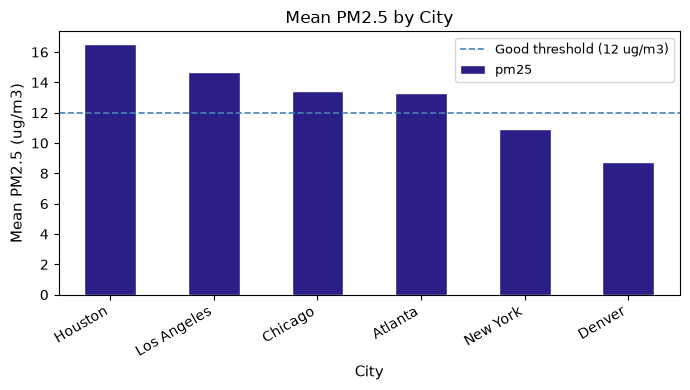

Saved: bar_output.png


In [8]:
# 4c. Create a bar chart showing mean PM2.5 by city.
#     Sort from highest to lowest (ascending=False).
#     Add a horizontal reference line at PM2.5 = 12.
#     Fill in the title and save the file as 'bar_output.png'.

fig, ax = plt.subplots(figsize=(7, 4))

city_means.sort_values(ascending=False).plot(
    kind='bar', ax=ax, color="#291F86", edgecolor='white'
)

ax.axhline(12, color='steelblue', linestyle='--', linewidth=1.2,
           label='Good threshold (12 ug/m3)')
ax.legend(fontsize=9)

ax.set_title('Mean PM2.5 by City')
ax.set_xlabel('City', fontsize=11)
ax.set_ylabel('Mean PM2.5 (ug/m3)', fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.savefig('bar_output.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: bar_output.png')

## Section 5: Code From Scratch

No blanks this time. You get the question only; write the full code yourself. This composes two things you have already done separately: filtering with a condition (the Filter + Aggregate pattern from the lecture) and `.groupby()` (Section 4).

**Question:** Using only the rows where `aq_category` is `'Good'`, compute the mean `ozone` level for each city. Which city has the highest mean ozone among its own "Good" days? Does every city appear in the result? If not, why not?

In [ ]:
# Write your own code below. No starter code or blanks are provided for this section.
#
# Filter df to rows where aq_category == 'Good'.
# Then group the filtered rows by city and compute mean ozone.
# Print the result.
aq_good_means = df[df['aq_category'] == 'Good'].groupby('city')['ozone'].mean().round(2)
print('Mean ozone by city (Good AQ):')
print(aq_good_means)

Mean ozone by city (Good AQ):
city
Atlanta        0.05
Chicago        0.04
Denver         0.06
Los Angeles    0.06
New York       0.04
Name: ozone, dtype: float64


**Reflection (one sentence):** Denver has the lowest average PM2.5 of all six cities. Based on what you just found, is Denver also the cleanest city on ozone, at least on its own best days? In one sentence, what does this tell you about judging "air quality" from a single measurement?

**Your answer:** Based on the result below Denver is not the clean city on ozone, no it not because the it has the highest average of ozone amount the cities. The single measurement can conduct to the wrong conclusion because the air quality change over time and depend on the location.

## Section 6: Interpret

Data visualization is only useful if you can say what it communicates. Answer each question below in 1-3 sentences. Write in plain English; do not copy code or column names verbatim.

**6a. What does the PM2.5 distribution (Section 2) tell you about air quality across all six cities combined? Are most readings in the Good, Moderate, or Unhealthy range?**

**Your answer:** The distribution show that all the six cities fall in the Good range, Some fall into the "moderate" category and a smaller number into the "unhealthy" category. Most values ​​are centered around 10–16 μg/m3, indicating generally good to moderate air quality, while readings above 15 μg/m3 suggest that, in some cities, air quality may be less good at times.

**6b. What relationship did you observe in the scatter plot (Section 3)? Why is it important to qualify your observation as a hypothesis rather than a finding at this sample size?**

**Your answer:** The relationship find are not strong. It's important because the sample size may be too smal to represent all the observations, and  the possible variation or pattern accross time and location may be ignore like our case.

**6c. Looking at the bar chart (Section 4), which city has the highest average PM2.5? How many cities exceed the EPA Good threshold of 12 ug/m3 on average? What would you investigate next if you were preparing a public health report?**

**Your answer:** Houston has the highest average of PM2.5. Four cities exceed the EPA Good threshold of  12 ug/m3 on average. I will investigate PM2.5 over time and the differents location and the risk it present for the population. 